# Módulo 46: Formato condicional

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio de este módulo: [enunciado](m46-formato-condicional-guia.ipynb) y [solución](m46-formato-condicional-solucion.ipynb). No es una tarea entregada del programa.

Una tabla con diez países y cuatro métricas tiene cuarenta números. Nadie los lee todos: el lector busca el más alto, el más bajo o el que se sale de lo normal. El **formato condicional** colorea las celdas según su valor para que esa búsqueda la haga el ojo, no la cabeza. Bien usado, ahorra segundos en cada lectura; mal usado, convierte la tabla en un mosaico que distrae. Esta lección muestra las opciones de **pandas** (`Styler`) y **Streamlit** (`st.dataframe` con `column_config`) con los datos de ventas por país, y termina con el primer dashboard de la sección.

1. Para qué sirve: la atención preatentiva
2. Dónde se aplica el formato
3. Escalas de color: secuenciales y divergentes
4. Reglas con umbrales
5. El color calculado por una función
6. Barras de datos e iconos
7. Accesibilidad
8. Mi primer dashboard en Streamlit
9. Errores frecuentes
10. Ejercicio

## 1. Para qué sirve: la atención preatentiva

El sistema visual detecta ciertos atributos **antes** de que pongamos atención consciente: el color, la intensidad, el tamaño, la posición o la orientación. Se llaman atributos **preatentivos**. Si en una columna de números grises uno es rojo, lo vemos en menos de un cuarto de segundo, sin recorrer la lista.

El formato condicional aprovecha ese mecanismo. Su objetivo no es decorar, sino responder una pregunta concreta:

| Pregunta del lector | Técnica adecuada |
| --- | --- |
| ¿Qué valores son altos y cuáles bajos? | Escala de color (degradado) |
| ¿Qué valores superan un umbral? | Reglas |
| ¿Cuál es la proporción entre valores? | Barras de datos |
| ¿Mejoró o empeoró? | Iconos o colores divergentes alrededor de cero |

Los datos de esta lección son las ventas totales por país de 2019 a 2021. `tabla_por_pais` de `ventas.py` devuelve las ventas por país; la participación de cada país en las ventas se calcula aquí:

In [1]:
import re
import sys
from pathlib import Path

import matplotlib as mpl
import pandas as pd
import plotly.express as px
import plotly.io as pio
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_hex

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

con = practica.conectar()

In [2]:
por_pais = practica.tabla_por_pais(con)
tabla = pd.DataFrame({
    "ventas_m": por_pais["ventas_total"].to_numpy() / 1e6,
    "pct_ventas": por_pais["ventas_total"].to_numpy() / por_pais["ventas_total"].sum(),
}, index=pd.Index(por_pais["pais"], name="pais"))
tabla.round({"ventas_m": 1, "pct_ventas": 4})

,ventas_m,pct_ventas
pais,,
FRANCE,6709.5,0.1600
CANADA,6683.5,0.1594
US,5025.3,0.1198
BRAZIL,4708.0,0.1123
CHILE,4690.6,0.1118
MEXICO,4655.6,0.1110
PORTUGAL,2401.5,0.0573
SPAIN,2360.7,0.0563
COLOMBIA,2357.4,0.0562


Sin color hay que leer las diez cifras para ver que forman tres grupos: FRANCE y CANADA cerca de 6 700 millones (16 % del total cada uno), cuatro países entre 4 650 y 5 030 millones (11–12 %) y cuatro cerca de 2 350–2 400 millones (5,6–5,7 %). Con color, los grupos saltan a la vista.

## 2. Dónde se aplica el formato

En Python el formato condicional de una tabla tiene dos destinos, con herramientas distintas:

| Dónde se ve la tabla | Herramienta | Qué admite |
| --- | --- | --- |
| Notebook, HTML exportado, `st.table` | `pandas.Styler` (`df.style`) | Todo el CSS: color de fondo y de fuente, barras, bordes, negritas |
| App de Streamlit con `st.dataframe` | `Styler` solo para colores + `column_config` para formato y barras | Color de fondo, color y peso de fuente; barras con `ProgressColumn` |
| Gráficos | Plotly (`color=`, `color_discrete_map=`) | Color por valor o por categoría |

Un `Styler` no cambia los datos: guarda una lista de reglas CSS por celda y las escribe al generar el HTML. Por eso se puede ver lo que calcula sin necesidad de un navegador:

In [3]:
estilo = tabla.style.set_uuid("demo").highlight_max(subset=["ventas_m"], color="#fdd49e")
print("\n".join(estilo.to_html().splitlines()[:5]))

<style type="text/css">
#T_demo_row0_col0 {
  background-color: #fdd49e;
}
</style>


`highlight_max` añadió `background-color: #fdd49e` a la fila 0, columna 0: FRANCE, el máximo de ventas.

> **Aviso: GitHub no muestra los colores de los `Styler`.** Al ver un notebook en GitHub, el HTML de las salidas pasa por un filtro que elimina las etiquetas `<style>`, así que las tablas aparecen con los números pero sin colores. En Jupyter, VS Code o al exportar el notebook a HTML sí se ven. Por eso, en esta lección cada formato importante se acompaña de los códigos de color en texto o de un gráfico de Plotly en PNG, que sí se ve en GitHub.

En Streamlit, `st.dataframe` acepta un `Styler`, pero solo traslada los colores de fondo, el color y el peso de la fuente; el formato de los números y las barras se configuran con `column_config`:

```python
st.dataframe(
    vista.style.background_gradient(subset=["ventas_mediana"], cmap="Blues"),   # color
    column_config={
        "ventas_mediana": st.column_config.NumberColumn("Mediana", format="%.0f"),  # formato
        "ventas_total": st.column_config.ProgressColumn("Ventas", min_value=0, max_value=6_710),  # barras
    },
)
```

## 3. Escalas de color: secuenciales y divergentes

Una **escala secuencial** va de un color claro (poco) a uno oscuro (mucho). Sirve para magnitudes que van de "poco" a "mucho", como las ventas: todos los valores son positivos y el interés está en el extremo alto. `background_gradient` colorea el fondo y `text_gradient`, el texto; las dos reciben un mapa de colores (`cmap`) de matplotlib.

In [4]:
tabla.style.background_gradient(subset=["ventas_m"], cmap="Blues").format({"ventas_m": "{:,.1f}", "pct_ventas": "{:.2%}"})

,ventas_m,pct_ventas
pais,,
FRANCE,"6,709.5",16.00%
CANADA,"6,683.5",15.94%
US,"5,025.3",11.98%
BRAZIL,"4,708.0",11.23%
CHILE,"4,690.6",11.18%
MEXICO,"4,655.6",11.10%
PORTUGAL,"2,401.5",5.73%
SPAIN,"2,360.7",5.63%
COLOMBIA,"2,357.4",5.62%


Como GitHub no muestra ese color, conviene saber reproducirlo. `background_gradient` normaliza cada valor entre el mínimo y el máximo (0 = mínimo, 1 = máximo) y busca ese punto en el mapa de colores. La función `colores` hace exactamente eso, y la comprobación final confirma que sus códigos coinciden con el CSS que genera el `Styler`:

In [5]:
def colores(valores, cmap, vmin=None, vmax=None):
    # Color hexadecimal que background_gradient asigna a cada valor
    vmin = valores.min() if vmin is None else vmin
    vmax = valores.max() if vmax is None else vmax
    mapa = mpl.colormaps[cmap] if isinstance(cmap, str) else cmap
    normalizar = Normalize(vmin, vmax)
    return valores.map(lambda v: to_hex(mapa(normalizar(v))))


def colores_del_styler(styler):
    # Lee del CSS el background-color de cada fila; pandas agrupa en una regla las celdas con el mismo estilo
    por_fila = {}
    for selectores, color in re.findall(r"([^{}]+)\{\s*background-color: (#[0-9a-f]{6})", styler.to_html()):
        for fila in re.findall(r"_row(\d+)_", selectores):
            por_fila[int(fila)] = color
    return [por_fila[i] for i in sorted(por_fila)]


secuencial = colores(tabla["ventas_m"], "Blues")
estilo = tabla[["ventas_m"]].style.background_gradient(cmap="Blues")
print("Coinciden con el Styler:", secuencial.tolist() == colores_del_styler(estilo))
secuencial.to_frame("color")

Coinciden con el Styler: True


,color
pais,
FRANCE,#08306b
CANADA,#08316d
US,#4594c7
BRAZIL,#5da5d1
CHILE,#5fa6d1
MEXICO,#61a7d2
PORTUGAL,#f5f9fe
SPAIN,#f7fbff
COLOMBIA,#f7fbff


FRANCE y CANADA quedan en los tonos más oscuros, los cuatro países de unos 4 700 millones en un tono medio y los cuatro de unos 2 400 millones en el más claro. El ojo agrupa sin leer.

**Límites automáticos frente a fijos.** Por defecto, el mínimo y el máximo de la escala son el valor más bajo y el más alto de los datos que se muestran. Si un filtro deja solo tres países pequeños, la escala vuelve a estirarse entre esos tres y un país mediocre parece el mejor. Con `vmin` y `vmax` fijos el color significa lo mismo con cualquier filtro:

In [6]:
pequenos = tabla.loc[["PORTUGAL", "SPAIN", "PERU"], "ventas_m"]
pd.DataFrame({
    "ventas_m": pequenos.round(1),
    "automatico": colores(pequenos, "Blues"),
    "fijo_0_a_max": colores(pequenos, "Blues", vmin=0, vmax=tabla["ventas_m"].max()),
})

,ventas_m,automatico,fijo_0_a_max
pais,,,
PORTUGAL,2401.5,#08306b,#a4cce3
SPAIN,2360.7,#cbdef1,#a5cde3
PERU,2348.8,#f7fbff,#a6cee4


Con límites automáticos, PORTUGAL recibe `#08306b`, el azul más oscuro de la escala, aunque vende poco más de un tercio que FRANCE. Con límites fijos (de 0 al máximo de los diez países) los tres quedan en azules claros y muy parecidos, que es lo que son. En un dashboard con filtros, los límites fijos son la opción segura; la app de la sección 8 los calcula sobre los diez países.

Una **escala divergente** tiene tres colores: dos extremos y un centro neutro. Es la adecuada cuando hay un punto de referencia con significado: cero en una variación, la meta en un cumplimiento, el promedio en una comparación. La variación de 2020 frente a 2019 tiene signos distintos:

In [7]:
anual = practica.ventas_por(con, ["pais", "anio"]).pivot(index="pais", columns="anio", values="ventas_total")
anual["var_2020"] = anual[2020] / anual[2019] - 1
anual["var_2021"] = anual[2021] / anual[2020] - 1
anual = anual.loc[tabla.index]
anual[["var_2020", "var_2021"]].round(4)

anio,var_2020,var_2021
pais,,
FRANCE,-0.6374,2.9862
CANADA,-0.6398,3.0300
US,0.1963,2.9464
BRAZIL,-0.7392,3.6648
CHILE,-0.7390,3.6641
MEXICO,-0.7415,3.6589
PORTUGAL,-0.8269,11.4277
SPAIN,-0.8210,11.0172
COLOMBIA,-0.8239,11.0511


Solo US creció en 2020 (+19,6 %); los otros nueve países cayeron entre un 64 % y un 83 %. Para valores con signo, la escala debe ser divergente y con el centro **fijado en 0**. `background_gradient` no tiene un parámetro para el centro: se consigue con límites simétricos, `vmin=-1` y `vmax=1`, de modo que el 0 cae justo en la mitad. El par naranja–azul se distingue con los tipos de daltonismo más comunes (sección 7):

In [8]:
NARANJA_BLANCO_AZUL = LinearSegmentedColormap.from_list("naranja_blanco_azul", ["#e66101", "#f7f7f7", "#2166ac"])

anual[["var_2020"]].style.background_gradient(cmap=NARANJA_BLANCO_AZUL, vmin=-1, vmax=1).format("{:+.1%}")

anio,var_2020
pais,
FRANCE,-63.7%
CANADA,-64.0%
US,+19.6%
BRAZIL,-73.9%
CHILE,-73.9%
MEXICO,-74.2%
PORTUGAL,-82.7%
SPAIN,-82.1%
COLOMBIA,-82.4%


In [9]:
pd.DataFrame({
    "var_2020": anual["var_2020"].round(3),
    "divergente_centrada_en_0": colores(anual["var_2020"], NARANJA_BLANCO_AZUL, vmin=-1, vmax=1),
})

,var_2020,divergente_centrada_en_0
pais,,
FRANCE,-0.637,#ec975a
CANADA,-0.640,#ec975a
US,0.196,#ccdae8
BRAZIL,-0.739,#ea8841
CHILE,-0.739,#ea8841
MEXICO,-0.742,#ea8841
PORTUGAL,-0.827,#e97b2b
SPAIN,-0.821,#e97b2b
COLOMBIA,-0.824,#e97b2b


US queda en un azul claro (creció poco) y los demás en naranjas, más intensos cuanto mayor fue la caída. La sección 9 muestra qué pasa si a esta misma columna se le aplica una escala secuencial.

| Escala | Colores | Límites | Ejemplo |
| --- | --- | --- | --- |
| Secuencial | Claro → oscuro (`Blues`, `viridis`, `cividis`) | Automáticos, o fijos si hay filtros | Ventas por país |
| Divergente | Naranja → blanco → azul | Simétricos alrededor del punto de referencia (`vmin=-v`, `vmax=v`) | Variación anual |

## 4. Reglas con umbrales

Con **reglas** se definen intervalos y un color por intervalo: "si el valor es mayor o igual que *a* y menor que *b*, entonces este color". Es la opción adecuada cuando existen umbrales de negocio. Para la tabla de países se pueden fijar tres niveles por participación en el total:

| Nivel | Condición sobre `pct_ventas` | Color |
| --- | --- | --- |
| Alto | ≥ 15 % | Azul oscuro |
| Medio | ≥ 10 % y < 15 % | Azul claro |
| Bajo | < 10 % | Gris |

Los intervalos deben cubrir todos los valores **sin huecos ni solapes**: cada límite es inclusivo (≥) por un lado y exclusivo (<) por el otro. En Python la regla se escribe como una función con `if` en orden, o con `pd.cut(..., right=False)`, que crea intervalos cerrados por la izquierda, `[a, b)`:

In [10]:
def nivel(p):
    if p >= 0.15:
        return "Alto"
    if p >= 0.10:
        return "Medio"
    return "Bajo"


tabla["nivel"] = tabla["pct_ventas"].map(nivel)
con_cut = pd.cut(tabla["pct_ventas"], bins=[0, 0.10, 0.15, 1], right=False, labels=["Bajo", "Medio", "Alto"])
print("La función y pd.cut coinciden:", (con_cut.astype(str) == tabla["nivel"]).all())
tabla.groupby("nivel", sort=False).size()

La función y pd.cut coinciden: True


nivel
Alto     2
Medio    4
Bajo     4
dtype: int64

`Styler.map` aplica una función **celda a celda**: recibe el valor y devuelve una regla CSS (o una cadena vacía para no dar formato). `Styler.apply` recibe una **columna o fila entera** y devuelve una lista de reglas, útil cuando el formato de una celda depende de las demás, como resaltar el máximo y el mínimo:

In [11]:
CSS_NIVEL = {
    "Alto": "background-color: #08519c; color: white",
    "Medio": "background-color: #6baed6",
    "Bajo": "background-color: #d9d9d9",
}


def extremos(columna):
    # Negrita en el máximo y cursiva en el mínimo de la columna
    return [
        "font-weight: bold" if v == columna.max() else "font-style: italic" if v == columna.min() else ""
        for v in columna
    ]


(
    tabla.style
    .map(lambda p: CSS_NIVEL[nivel(p)], subset=["pct_ventas"])
    .apply(extremos, subset=["ventas_m"])
    .format({"ventas_m": "{:,.1f}", "pct_ventas": "{:.2%}"})
)

,ventas_m,pct_ventas,nivel
pais,,,
FRANCE,"6,709.5",16.00%,Alto
CANADA,"6,683.5",15.94%,Alto
US,"5,025.3",11.98%,Medio
BRAZIL,"4,708.0",11.23%,Medio
CHILE,"4,690.6",11.18%,Medio
MEXICO,"4,655.6",11.10%,Medio
PORTUGAL,"2,401.5",5.73%,Bajo
SPAIN,"2,360.7",5.63%,Bajo
COLOMBIA,"2,357.4",5.62%,Bajo


FRANCE y CANADA quedan en el nivel alto; US, BRAZIL, CHILE y MEXICO, en el medio, y los otros cuatro, en el bajo. Conviene expresar los umbrales como **números** (0.15) y no como "el 15 % del rango de valores": son cosas distintas y la diferencia confunde a quien mantiene el código.

## 5. El color calculado por una función

El paso siguiente es separar la lógica del color en una función propia que devuelva un **código de color**. Es lo que en una herramienta de BI sería "el color desde una medida": la lógica vive en un solo lugar, se reutiliza en la tabla, en el gráfico y en la app, y puede depender de otros valores.

In [12]:
COLOR_NIVEL = {"Alto": "#08519c", "Medio": "#6baed6", "Bajo": "#bdbdbd"}


def color_participacion(p):
    # Código de color según la participación en las ventas; None si no hay dato
    if pd.isna(p):
        return None
    return COLOR_NIVEL[nivel(p)]


tabla["color"] = tabla["pct_ventas"].map(color_participacion)
tabla.loc[["FRANCE", "US", "PERU"], ["pct_ventas", "nivel", "color"]]

,pct_ventas,nivel,color
pais,,,
FRANCE,0.159974,Alto,#08519c
US,0.119819,Medio,#6baed6
PERU,0.056004,Bajo,#bdbdbd


La columna que se colorea no tiene por qué ser la que decide el color. Con `apply(axis=1)` la función recibe la fila completa, así que se puede pintar la columna de ventas según la participación:

In [13]:
def fondo_segun_participacion(fila):
    color = color_participacion(fila["pct_ventas"])
    texto = "white" if fila["nivel"] == "Alto" else "black"
    return [f"background-color: {color}; color: {texto}" if col == "ventas_m" else "" for col in fila.index]


tabla[["ventas_m", "pct_ventas", "nivel"]].style.apply(fondo_segun_participacion, axis=1).format(
    {"ventas_m": "{:,.1f}", "pct_ventas": "{:.2%}"}
)

,ventas_m,pct_ventas,nivel
pais,,,
FRANCE,"6,709.5",16.00%,Alto
CANADA,"6,683.5",15.94%,Alto
US,"5,025.3",11.98%,Medio
BRAZIL,"4,708.0",11.23%,Medio
CHILE,"4,690.6",11.18%,Medio
MEXICO,"4,655.6",11.10%,Medio
PORTUGAL,"2,401.5",5.73%,Bajo
SPAIN,"2,360.7",5.63%,Bajo
COLOMBIA,"2,357.4",5.62%,Bajo


Como la función devuelve códigos de color, el mismo criterio sirve para un gráfico. Unas barras horizontales coloreadas por nivel transmiten lo mismo que la tabla y, al ser una imagen PNG, se ven también en GitHub:

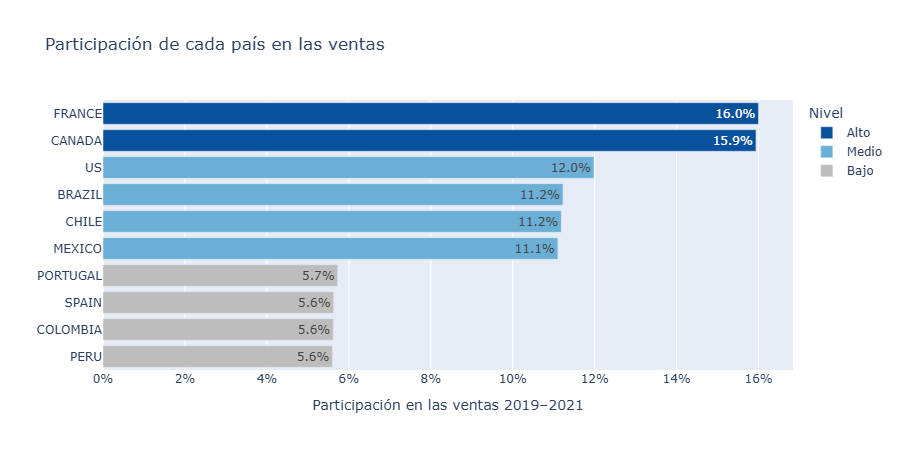

In [14]:
orden = tabla.sort_values("pct_ventas")
fig = px.bar(
    orden.reset_index(), x="pct_ventas", y="pais", orientation="h", color="nivel",
    color_discrete_map=COLOR_NIVEL, text_auto=".1%",
    labels={"pct_ventas": "Participación en las ventas 2019–2021", "pais": "", "nivel": "Nivel"},
    category_orders={"nivel": ["Alto", "Medio", "Bajo"], "pais": orden.index[::-1].tolist()},
    title="Participación de cada país en las ventas",
)
fig.update_xaxes(tickformat=".0%")
fig.show()

Si mañana el umbral del nivel alto pasa de 15 % a 14 %, se cambia en `nivel` y se actualizan a la vez la tabla, el gráfico y la app.

## 6. Barras de datos e iconos

Las **barras de datos** dibujan dentro de la celda una barra proporcional al valor. Convierten la tabla en un pequeño gráfico de barras sin perder el número exacto. `Styler.bar` las dibuja con un degradado CSS; con `vmin=0` la longitud es proporcional al valor, y con `align="zero"` y dos colores sirve para valores con signo:

In [15]:
pd.concat([tabla[["ventas_m"]], anual[["var_2020"]]], axis=1).style.bar(
    subset=["ventas_m"], color="#6baed6", vmin=0
).bar(
    subset=["var_2020"], align="zero", color=["#e66101", "#2166ac"]
).format({"ventas_m": "{:,.1f}", "var_2020": "{:+.1%}"})

,ventas_m,var_2020
pais,,
FRANCE,"6,709.5",-63.7%
CANADA,"6,683.5",-64.0%
US,"5,025.3",+19.6%
BRAZIL,"4,708.0",-73.9%
CHILE,"4,690.6",-73.9%
MEXICO,"4,655.6",-74.2%
PORTUGAL,"2,401.5",-82.7%
SPAIN,"2,360.7",-82.1%
COLOMBIA,"2,357.4",-82.4%


Con las barras se ve de inmediato que FRANCE vende casi tres veces lo que PERU:

In [16]:
print(f"FRANCE / PERU = {tabla.loc['FRANCE', 'ventas_m'] / tabla.loc['PERU', 'ventas_m']:.2f}")

FRANCE / PERU = 2.86


`st.dataframe` **no dibuja** las barras de `Styler.bar`. En Streamlit se usa `st.column_config.ProgressColumn`, con `min_value` y `max_value` explícitos (sección 9):

```python
st.dataframe(vista, column_config={
    "ventas_total": st.column_config.ProgressColumn("Ventas (M)", format="%.1f", min_value=0, max_value=6_710),
})
```

Los **iconos** se asignan con reglas, como en la sección 4, y son útiles para estados discretos: subió, bajó o se mantuvo. Una tolerancia evita que una variación de +0,1 % aparezca como subida:

In [17]:
def icono(v, tolerancia=0.01):
    if pd.isna(v):
        return ""
    if v > tolerancia:
        return "▲"
    if v < -tolerancia:
        return "▼"
    return "▬"


pd.DataFrame({
    "2020 vs 2019": anual["var_2020"].map(lambda v: f"{icono(v)} {v:+.1%}"),
    "2021 vs 2020": anual["var_2021"].map(lambda v: f"{icono(v)} {v:+.1%}"),
})

,2020 vs 2019,2021 vs 2020
pais,,
FRANCE,▼ -63.7%,▲ +298.6%
CANADA,▼ -64.0%,▲ +303.0%
US,▲ +19.6%,▲ +294.6%
BRAZIL,▼ -73.9%,▲ +366.5%
CHILE,▼ -73.9%,▲ +366.4%
MEXICO,▼ -74.2%,▲ +365.9%
PORTUGAL,▼ -82.7%,▲ +1142.8%
SPAIN,▼ -82.1%,▲ +1101.7%
COLOMBIA,▼ -82.4%,▲ +1105.1%


| Icono | Regla sobre la variación |
| --- | --- |
| ▲ | > +1 % |
| ▬ | entre −1 % y +1 % |
| ▼ | < −1 % |

En 2021 todos los países subieron; en 2020 solo US. Un icono no depende solo del color: la forma de la flecha comunica lo mismo a quien no distingue los colores, y se ve igual en GitHub, en un PDF o en una impresión en blanco y negro.

## 7. Accesibilidad

Alrededor del 8 % de los hombres tiene algún tipo de daltonismo, el más común con dificultad para distinguir rojo y verde. Un semáforo rojo–verde, la elección más habitual, es justo la que más falla.

| Recomendación | Cómo aplicarla |
| --- | --- |
| Evitar el par rojo–verde | Azul–naranja para escalas divergentes; `viridis` o `cividis` para secuenciales |
| No depender solo del color | Añadir iconos, etiquetas o el propio número |
| Cuidar el contraste del texto | WCAG pide un contraste mínimo de 4.5:1 para texto normal |
| Pocos colores con significado | Tres niveles se distinguen; siete no |

El contraste se puede calcular. La fórmula de WCAG compara la luminancia relativa de los dos colores y va de 1:1 (iguales) a 21:1 (negro sobre blanco):

In [18]:
def luminancia(color):
    # Luminancia relativa según WCAG 2.x
    canales = [c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4 for c in mpl.colors.to_rgb(color)]
    return 0.2126 * canales[0] + 0.7152 * canales[1] + 0.0722 * canales[2]


def contraste(texto, fondo):
    claro, oscuro = sorted([luminancia(texto), luminancia(fondo)], reverse=True)
    return (claro + 0.05) / (oscuro + 0.05)


fondos = {"Blues mínimo": "#f7fbff", "Medio": "#6baed6", "Alto": "#08519c", "Blues máximo": "#08306b"}
pd.DataFrame({
    "texto_negro": {nombre: contraste("black", c) for nombre, c in fondos.items()},
    "texto_blanco": {nombre: contraste("white", c) for nombre, c in fondos.items()},
}).round(1)

,texto_negro,texto_blanco
Blues mínimo,20.2,1.0
Medio,8.7,2.4
Alto,2.7,7.9
Blues máximo,1.6,12.8


El texto negro es ilegible sobre el azul más oscuro y el blanco lo es sobre el más claro. `background_gradient` lo resuelve solo: su parámetro `text_color_threshold` (0.408 por defecto) cambia el texto a un blanco casi puro (`#f1f1f1`) cuando el fondo es oscuro. En el HTML de la sección 3 se ve:

In [19]:
html = tabla[["ventas_m"]].style.background_gradient(cmap="Blues").to_html()
print("Colores de texto usados:", sorted(set(re.findall(r"color: (#[0-9a-f]{6});\n}", html))))

Colores de texto usados: ['#000000', '#f1f1f1']


Con `text_gradient` el riesgo es el contrario: los colores claros del mapa (el blanco de `Blues`) desaparecen sobre un fondo blanco. Por eso la app usa para el color de fuente una escala propia cuyos dos extremos son oscuros:

In [20]:
for color in ["#b35806", "#2166ac"]:
    print(color, "sobre blanco:", round(contraste(color, "white"), 1))

#b35806 sobre blanco: 4.9
#2166ac sobre blanco: 5.9


Los dos superan 4.5:1. Por último, conviene respetar las convenciones del público: en finanzas el rojo significa pérdida, y una escala que pinte de rojo a los países que más venden se leería al revés.

## 8. Mi primer dashboard en Streamlit

El ejercicio del módulo es un dashboard completo: [`m46-formato-condicional-app.py`](m46-formato-condicional-app.py). Se ejecuta desde la raíz del repositorio:

```bash
uv run streamlit run s08-dashboards/m46-formato-condicional/m46-formato-condicional-app.py
```

Para no copiar el código en este notebook (y que nunca deje de coincidir con la app), la celda siguiente lee el archivo y lo divide en sus partes, marcadas con comentarios `# --- N. ... ---`:

In [21]:
codigo = Path("m46-formato-condicional-app.py").read_text(encoding="utf-8")
partes = re.split(r"\n(?=[ \t]*# --- \d)", codigo)


def mostrar(n):
    print(partes[n].strip("\n"))


print(len(partes) - 1, "partes:", [p.strip().splitlines()[0].strip() for p in partes[1:]])

7 partes: ['# --- 1. Configuración, conexión y consultas en caché ---', '# --- 2. Encabezado y filtro de países ---', '# --- 3. Indicadores clave ---', '# --- 4. Mapa de burbujas y anillo por categoría ---', '# --- 5. Tendencia de ventas con granularidad ---', '# --- 6. Tabla por país con formato condicional ---', '# --- 7. Descarga de la tabla filtrada ---']


**Parte 1. Configuración, conexión y consultas en caché.** Streamlit vuelve a ejecutar el script entero con cada clic. Para que eso sea rápido, la conexión a DuckDB se abre una sola vez con `@st.cache_resource` (un recurso compartido) y cada consulta se guarda con `@st.cache_data` (un resultado que se puede copiar). El guion bajo de `_con` le dice a Streamlit que no intente usar la conexión como parte de la clave de la caché; los países llegan como tupla para que sí formen parte de ella. La app nunca trae a pandas las 1,5 millones de filas: DuckDB agrega y devuelve diez filas o unos cientos de periodos.

In [22]:
mostrar(1)

# --- 1. Configuración, conexión y consultas en caché ---
st.set_page_config(page_title="Mi primer dashboard", page_icon=":material/bar_chart:", layout="wide")

# Escala de dos colores para el texto: los dos extremos contrastan con un fondo blanco
NARANJA_AZUL = LinearSegmentedColormap.from_list("naranja_azul", ["#b35806", "#2166ac"])
GRANULARIDAD = {"Día": "day", "Mes": "month", "Año": "year"}


@st.cache_resource
def conexion():
    # Una sola conexión DuckDB para todas las sesiones; ventas.py abre un cursor por consulta
    return practica.conectar()


@st.cache_data
def lista_paises(_con):
    return sorted(practica.tabla_por_pais(_con)["pais"])


@st.cache_data
def leer_kpis(_con, paises):
    return practica.kpis(_con, paises=paises)


@st.cache_data
def leer_tabla(_con, paises):
    return practica.tabla_por_pais(_con, paises=paises)


@st.cache_data
def leer_categorias(_con, paises):
    return practica.ventas_por(_con, "categoria", paises=paises)


@st.cache_data
def leer_seri

**Parte 2. Encabezado y filtro de países.** El filtro va en la barra lateral, como un segmentador de una herramienta de BI. En `ventas.py` una lista vacía no deja pasar ninguna fila (es lo correcto para la seguridad por filas del Módulo 50); en la interfaz, en cambio, "no elegir nada" significa "todos", así que la app traduce la lista vacía a `None`.

In [23]:
mostrar(2)

# --- 2. Encabezado y filtro de países ---
st.title("Mi primer dashboard")
st.caption("Autor: Juliho Castillo Colmenares · Ventas de una cadena de tiendas, 2019–2021")

with st.sidebar:
    st.header("Filtros")
    seleccion = st.multiselect(
        "Países",
        lista_paises(con),
        placeholder="Todos los países",
        help="Sin selección se muestran los diez países.",
        key="paises",
    )
# En ventas.py una lista vacía no deja pasar ninguna fila; aquí "nada elegido" significa "todos"
paises = tuple(sorted(seleccion)) if seleccion else None


**Parte 3. Indicadores clave.** Tres `st.metric` con borde en un contenedor horizontal, que se reparte en filas en pantallas estrechas. El formato se hace en Python (`millones`), así que lo que se ve es exactamente la cadena que se pasa.

In [24]:
mostrar(3)

# --- 3. Indicadores clave ---
kpis = leer_kpis(con, paises)
with st.container(horizontal=True):
    st.metric("Ventas totales", millones(kpis["ventas_total"]), border=True)
    st.metric("Cantidad total", millones(kpis["cantidad_total"]), border=True)
    st.metric("Mediana del precio", f"{kpis['precio_mediana']:,.0f}".replace(",", " "), border=True)


**Parte 4. Mapa de burbujas y anillo.** `px.scatter_geo` ubica cada país por su código ISO-3 y el tamaño de la burbuja es proporcional a las ventas. El anillo es un `px.pie` con `hole=0.5`, con etiquetas de valor y porcentaje. Los dos reciben los datos ya filtrados.

In [25]:
mostrar(4)

# --- 4. Mapa de burbujas y anillo por categoría ---
tabla = leer_tabla(con, paises)
categorias = leer_categorias(con, paises)

izquierda, derecha = st.columns(2)
with izquierda.container(border=True):
    st.subheader("Ventas por país")
    mapa = px.scatter_geo(
        tabla,
        locations="iso3",
        size="ventas_total",
        hover_name="pais",
        hover_data={"iso3": False, "ventas_total": ":,.0f"},
        projection="natural earth",
        size_max=40,
    )
    mapa.update_layout(margin=dict(l=0, r=0, t=0, b=0), height=360)
    st.plotly_chart(mapa, alt="Mapa de burbujas con las ventas totales de cada país")

with derecha.container(border=True):
    st.subheader("Cantidad por categoría")
    anillo = px.pie(categorias, names="categoria", values="cantidad_total", hole=0.5)
    anillo.update_traces(texttemplate="%{value:,.0f}<br>%{percent:.1%}")
    anillo.update_layout(margin=dict(l=0, r=0, t=0, b=0), height=360)
    st.plotly_chart(anillo, alt="Gráfico de anillo

**Parte 5. Tendencia de ventas.** `st.segmented_control` deja elegir la granularidad entre día, mes y año; con `required=True` siempre hay una opción elegida. `serie_temporal` hace el `date_trunc` en DuckDB.

In [26]:
mostrar(5)

# --- 5. Tendencia de ventas con granularidad ---
with st.container(border=True):
    st.subheader("Tendencia de ventas")
    etiqueta = st.segmented_control(
        "Granularidad", list(GRANULARIDAD), default="Mes", required=True, key="granularidad"
    )
    serie = leer_serie(con, GRANULARIDAD[etiqueta], paises)
    linea = px.line(serie, x="periodo", y="ventas_total", labels={"periodo": "", "ventas_total": "Ventas"})
    linea.update_layout(margin=dict(l=0, r=0, t=10, b=0), height=320)
    st.plotly_chart(linea, alt=f"Línea con las ventas totales por {etiqueta.lower()}")


**Parte 6. Tabla con tres formatos condicionales.** Cada formato responde a una pregunta distinta:

| Columna | Formato | Herramienta | Límites |
| --- | --- | --- | --- |
| Mediana de ventas | Color de fondo con degradado | `Styler.background_gradient` | Fijos: de 0 al máximo de los diez países |
| Ventas totales | Barras de datos | `ProgressColumn` | Fijos: de 0 al máximo de los diez países |
| % de la cantidad | Color de fuente | `Styler.text_gradient` | ±10 % alrededor del reparto uniforme (1 / número de países) |

El porcentaje de cantidad merece un comentario: los diez países venden casi la misma cantidad (entre 9,9 % y 10,1 % del total). Con límites automáticos, `text_gradient` estiraría esa diferencia de dos décimas por toda la escala y haría parecer opuestos a países prácticamente iguales. Con límites a ±10 % del reparto uniforme, todos quedan cerca del centro, que es la lectura honesta.

In [27]:
mostrar(6)

# --- 6. Tabla por país con formato condicional ---
# Límites fijos, calculados sobre los diez países: el color no cambia de significado al filtrar
completa = leer_tabla(con, None)
max_mediana = float(completa["ventas_mediana"].max())
max_ventas = float(completa["ventas_total"].max()) / 1e6
uniforme = 1 / len(tabla)  # participación de cada país si todos vendieran lo mismo

vista = tabla[["pais", "ventas_mediana", "ventas_total", "pct_cantidad"]].assign(
    ventas_total=tabla["ventas_total"] / 1e6
)
estilo = (
    vista.style
    .background_gradient(subset=["ventas_mediana"], cmap="Blues", vmin=0, vmax=max_mediana)
    .text_gradient(subset=["pct_cantidad"], cmap=NARANJA_AZUL, vmin=0.9 * uniforme, vmax=1.1 * uniforme)
)

with st.container(border=True):
    st.subheader("Ventas por país")
    st.dataframe(
        estilo,
        hide_index=True,
        column_config={
            "pais": st.column_config.TextColumn("País"),
            "ventas_mediana": st.column_config.NumberColumn

**Parte 7. Descarga.** `st.download_button` entrega la tabla filtrada en CSV, el equivalente a "exportar" el informe. Con `on_click="ignore"`, descargar no vuelve a ejecutar la app.

In [28]:
mostrar(7)

    # --- 7. Descarga de la tabla filtrada ---
    st.download_button(
        "Descargar CSV",
        data=tabla.drop(columns="ventas_promedio").to_csv(index=False).encode("utf-8"),
        file_name="ventas-por-pais.csv",
        mime="text/csv",
        icon=":material/download:",
        on_click="ignore",
    )


`AppTest` ejecuta la app sin navegador y permite simular la interacción. La prueba comprueba que no hay excepciones, lee las métricas, cambia la granularidad y filtra dos países:

In [29]:
import logging

from streamlit.testing.v1 import AppTest

# Silencia el aviso "missing ScriptRunContext", normal al ejecutar Streamlit fuera de un servidor
logging.getLogger("streamlit.runtime.scriptrunner_utils.script_run_context").setLevel(logging.ERROR)

app = AppTest.from_file(str(Path("m46-formato-condicional-app.py").resolve()), default_timeout=60).run()
print("Excepciones:", len(app.exception))
for metrica in app.metric:
    print(f"  {metrica.label}: {metrica.value}")

app.segmented_control(key="granularidad").set_value("Año").run()
app.multiselect(key="paises").set_value(["FRANCE", "US"]).run()
print("\nCon FRANCE y US, por año. Excepciones:", len(app.exception))
for metrica in app.metric:
    print(f"  {metrica.label}: {metrica.value}")
app.dataframe[0].value

Excepciones: 0
  Ventas totales: 41 941.0 M
  Cantidad total: 148.1 M
  Mediana del precio: 218



Con FRANCE y US, por año. Excepciones: 0
  Ventas totales: 11 734.8 M
  Cantidad total: 29.8 M
  Mediana del precio: 367


,pais,ventas_mediana,ventas_total,pct_cantidad
0,FRANCE,22747.0,6709.452115,0.499884
1,US,18060.0,5025.305951,0.500116


La métrica de ventas totales pasa de `41 941.0 M` a `11 734.8 M` y la tabla se reduce a dos filas. Con dos países el reparto uniforme es del 50 %, y los dos están a menos de una décima de ese valor.

## 9. Errores frecuentes

**Colorear todo.** Si las cuatro columnas de una tabla tienen degradado, ninguna destaca. El formato condicional funciona por contraste con lo que no tiene formato: se colorea la columna que responde a la pregunta principal y las demás se dejan neutras.

**Usar una escala secuencial para una variación.** Con `Blues` y límites automáticos, US, el único país que creció, recibe el azul más oscuro, y los nueve que cayeron reciben azules claros, de `#d3e3f3` a `#f7fbff`. Nada en el color dice dónde está el cero: el lector no distingue si un país creció o decreció.

In [30]:
pd.DataFrame({
    "var_2020": anual["var_2020"].round(3),
    "secuencial_automatica": colores(anual["var_2020"], "Blues"),
    "divergente_centrada_en_0": colores(anual["var_2020"], NARANJA_BLANCO_AZUL, vmin=-1, vmax=1),
}).loc[["US", "FRANCE", "PORTUGAL"]]

,var_2020,secuencial_automatica,divergente_centrada_en_0
pais,,,
US,0.196,#08306b,#ccdae8
FRANCE,-0.637,#d3e3f3,#ec975a
PORTUGAL,-0.827,#f7fbff,#e97b2b


**Dejar los límites automáticos cuando hay filtros.** Como se vio en la sección 3, el mismo valor cambia de color según lo que se haya filtrado. Si el color tiene que significar algo estable, se fijan `vmin` y `vmax`.

**Reglas con huecos.** Escribir `> 0.10` en una regla y `< 0.10` en la otra deja sin nivel al 10 % exacto. La función devuelve `None` y la celda se queda sin formato, sin ningún aviso:

In [31]:
def nivel_con_hueco(p):
    if p > 0.10:
        return "Medio o alto"
    if p < 0.10:
        return "Bajo"


print("0.10 con hueco:", nivel_con_hueco(0.10), "| sin hueco:", nivel(0.10))

0.10 con hueco: None | sin hueco: Medio


**Un código de color mal escrito.** El `Styler` no valida los colores: escribe `background-color: #08519` en el CSS y el navegador simplemente lo ignora. Plotly, en cambio, sí falla. `matplotlib.colors.is_color_like` sirve para validar la función de color antes de usarla:

In [32]:
print("'#08519' es un color válido:", mpl.colors.is_color_like("#08519"))
try:
    px.bar(orden.reset_index(), x="pct_ventas", y="pais", color="nivel",
           color_discrete_map={"Alto": "#08519", "Medio": "#6baed6", "Bajo": "#bdbdbd"}).to_image(format="png")
except ValueError as error:
    print("Plotly:", " ".join(str(error).split())[:110], "...")

'#08519' es un color válido: False
Plotly: Invalid value of type 'builtins.str' received for the 'color' property of bar.marker Received value: '#08519'  ...


**Usar `applymap`.** En pandas 2.1 `Styler.applymap` pasó a llamarse `Styler.map`; el nombre antiguo sigue funcionando pero avisa de que desaparecerá:

In [33]:
import warnings

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    tabla[["pct_ventas"]].style.applymap(lambda p: CSS_NIVEL[nivel(p)]).to_html()
print(avisos[0].category.__name__, "-", avisos[0].message)

FutureWarning - Styler.applymap has been deprecated. Use Styler.map instead.


**Esperar que `st.dataframe` dibuje un `Styler.bar`.** Streamlit ignora las barras del `Styler` (y también los formatos numéricos si la columna tiene `column_config`). Las barras se piden con `ProgressColumn`, y con `max_value` explícito: si se omite, el máximo es 100 para columnas enteras y 1.0 para decimales, y con ventas de millones todas las barras salen llenas.

## 10. Ejercicio

Se quiere una tabla con la variación de ventas de 2021 frente a 2020 por país. Los datos, en millones:

In [34]:
ejercicio = (anual[[2020, 2021]] / 1e6).rename(columns={2020: "ventas_2020_m", 2021: "ventas_2021_m"})
ejercicio.round(1)

anio,ventas_2020_m,ventas_2021_m
pais,,
FRANCE,866.4,3453.6
CANADA,856.2,3450.5
US,869.1,3429.8
BRAZIL,495.6,2311.9
CHILE,493.9,2303.8
MEXICO,488.6,2276.5
PORTUGAL,125.0,1554.1
SPAIN,126.9,1524.9
COLOMBIA,125.9,1516.8


1. Calcula la variación anual de cada país.
2. Elige la escala de color adecuada para esa variación y justifica la elección.
3. Escribe una función que devuelva un color con tres niveles: crecimiento superior a 1000 %, entre 300 % y 1000 %, e inferior a 300 %. Usa colores aptos para daltonismo y aplícala con un `Styler`.
4. Indica qué agregarías para que la información no dependa solo del color, y dibuja un gráfico que se vea también en GitHub.

### Solución

1. Variación = ventas 2021 / ventas 2020 − 1:

In [35]:
ejercicio["variacion"] = ejercicio["ventas_2021_m"] / ejercicio["ventas_2020_m"] - 1


def nivel_variacion(v):
    # Una variación de 1000 % es 10 en los datos: el porcentaje es solo el formato
    if v > 10:
        return "Alto"
    if v >= 3:
        return "Medio"
    return "Bajo"


COLOR_VARIACION = {"Alto": "#08519c", "Medio": "#6baed6", "Bajo": "#fd8d3c"}
ejercicio["nivel"] = ejercicio["variacion"].map(nivel_variacion)
ejercicio = ejercicio.sort_values("variacion", ascending=False)
ejercicio[["variacion", "nivel"]].assign(variacion=lambda t: t["variacion"].map("{:.1%}".format))

anio,variacion,nivel
pais,,
PORTUGAL,1142.8%,Alto
COLOMBIA,1105.1%,Alto
SPAIN,1101.7%,Alto
PERU,1100.4%,Alto
BRAZIL,366.5%,Medio
CHILE,366.4%,Medio
MEXICO,365.9%,Medio
CANADA,303.0%,Medio
FRANCE,298.6%,Bajo


Cuatro países superan el 1000 % (PORTUGAL, COLOMBIA, SPAIN y PERU, que partían de unos 125 millones en 2020), cuatro quedan entre 300 % y 1000 % (BRAZIL, CHILE, MEXICO y CANADA, este con 303,0 %) y dos quedan por debajo de 300 % (FRANCE con 298,6 % y US con 294,6 %).

2. Todos los valores son positivos y no hay un cero que separe crecimiento de caída, así que basta una escala secuencial o, mejor, **reglas**, porque el enunciado define umbrales. Una escala divergente centrada en 0 no aportaría nada: todos los países quedarían del mismo lado.

3. La función devuelve el código de color del nivel; el par azul–naranja se distingue con los tipos de daltonismo más comunes. Los intervalos no tienen huecos: 1000 % exacto es "Medio" y 300 % exacto también.

In [36]:
def color_variacion(v):
    if pd.isna(v):
        return None
    return COLOR_VARIACION[nivel_variacion(v)]


ejercicio["color"] = ejercicio["variacion"].map(color_variacion)
ejercicio[["variacion"]].style.map(
    lambda v: f"background-color: {color_variacion(v)}; color: {'white' if v > 10 else 'black'}"
).format("{:.1%}")

anio,variacion
pais,
PORTUGAL,1142.8%
COLOMBIA,1105.1%
SPAIN,1101.7%
PERU,1100.4%
BRAZIL,366.5%
CHILE,366.4%
MEXICO,365.9%
CANADA,303.0%
FRANCE,298.6%


4. Se muestra la variación como número junto al color y un icono por nivel, y se dibujan las barras coloreadas por nivel, que se ven en GitHub y en blanco y negro (la longitud de la barra lleva el dato aunque se pierda el color):

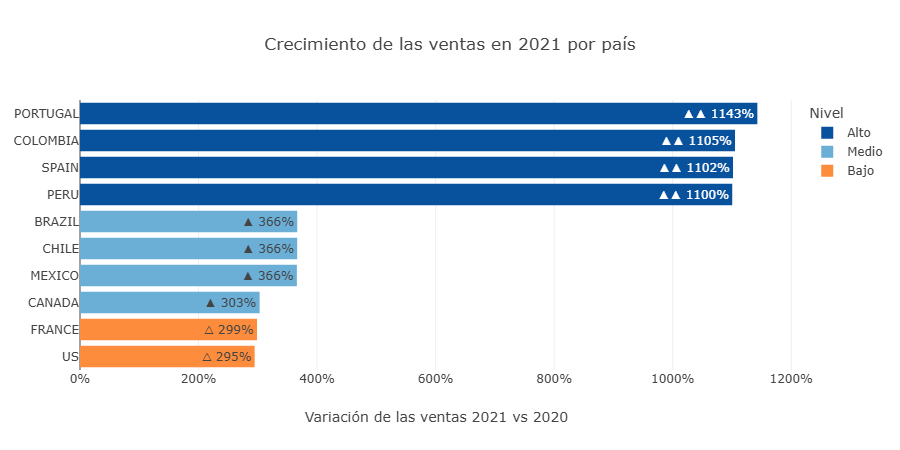

In [37]:
ICONO_NIVEL = {"Alto": "▲▲", "Medio": "▲", "Bajo": "△"}
ejercicio["etiqueta"] = ejercicio.apply(lambda f: f"{ICONO_NIVEL[f['nivel']]} {f['variacion']:.0%}", axis=1)

fig = px.bar(
    ejercicio.reset_index().sort_values("variacion"), x="variacion", y="pais", orientation="h",
    color="nivel", color_discrete_map=COLOR_VARIACION, text="etiqueta",
    category_orders={"nivel": ["Alto", "Medio", "Bajo"], "pais": ejercicio.index.tolist()},
    labels={"variacion": "Variación de las ventas 2021 vs 2020", "pais": "", "nivel": "Nivel"},
    title="Crecimiento de las ventas en 2021 por país",
)
fig.update_xaxes(tickformat=".0%")
fig.show()

## Resumen

- El formato condicional usa atributos preatentivos, sobre todo el color, para que los valores importantes se vean sin leer toda la tabla.
- En notebooks, `pandas.Styler` admite todo el CSS; en Streamlit, `st.dataframe` toma del `Styler` solo los colores, y el formato y las barras se configuran con `column_config` (`NumberColumn`, `ProgressColumn`).
- Las escalas secuenciales (`background_gradient`, `text_gradient`) sirven para magnitudes; las divergentes, centradas con `vmin=-v` y `vmax=v`, para valores con un punto de referencia. Con filtros, los límites deben ser fijos.
- Las reglas expresan umbrales de negocio con `Styler.map` o `apply`, sin huecos: un límite inclusivo y otro exclusivo.
- Una función que devuelve códigos de color centraliza la lógica y sirve a la vez para la tabla, el gráfico y la app.
- Barras de datos e iconos complementan al color; la accesibilidad pide evitar rojo–verde, cuidar el contraste y no depender solo del color. GitHub no muestra los colores de los `Styler`: un gráfico en PNG o los códigos de color en texto lo compensan.

En el **Módulo 47** se estudian a fondo las medidas y los KPI: cómo definirlas una vez en `ventas.py`, cómo responden a los filtros y cómo se calculan comparaciones en el tiempo, como el mes anterior o el acumulado del año.